In [1]:
import sys
from pathlib import Path
here = Path.cwd()
ROOT = next(p for p in [here, *here.parents] if (p / "src" / "model.py").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from src.data import ORDERS_PATH, TARGET
from src.model import FEATURES, CATEGORICAL, time_split, make_boosting

orders = pd.read_csv(ORDERS_PATH, parse_dates=["order_date"])
train, test = time_split(orders)
model = make_boosting().fit(train[FEATURES], train[TARGET])

prep, booster = model.named_steps["prep"], model.named_steps["model"]
sample = test.sample(2000, random_state=42)
X = pd.DataFrame(prep.transform(sample[FEATURES]), columns=prep.get_feature_names_out(), index=sample.index)
explainer = shap.TreeExplainer(booster)
sv = explainer(X)
print(sv.values.shape)

(2000, 136)


In [2]:
def original_feature(name):
    kind, rest = name.split("__", 1)                     # "cat__shipping_mode_First Class" → "cat", "shipping_mode_First Class"
    return rest if kind == "num" else next(c for c in CATEGORICAL if rest.startswith(c + "_"))

importance = (pd.Series(np.abs(sv.values).mean(axis=0), index=X.columns)
                .groupby(original_feature).sum()
                .sort_values(ascending=False))
importance.round(3)

shipping_mode        2.376
order_hour           0.233
order_value          0.032
total_qty            0.030
avg_discount_rate    0.029
country              0.024
region               0.014
scheduled_days       0.012
payment_type         0.012
main_department      0.011
order_month          0.009
order_dow            0.008
market               0.006
segment              0.004
n_items              0.003
n_departments        0.002
dtype: float64

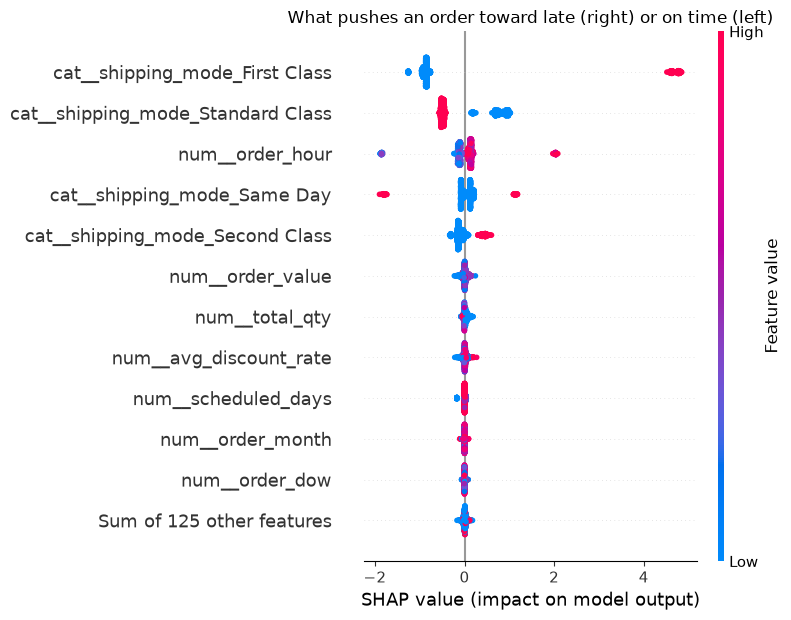

In [3]:
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("What pushes an order toward late (right) or on time (left)")
plt.tight_layout()
plt.savefig(ROOT / "docs" / "shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

shipping_mode           Same Day
order_hour                    20
region           Northern Europe
order_value           492.049999
Name: 50964, dtype: object


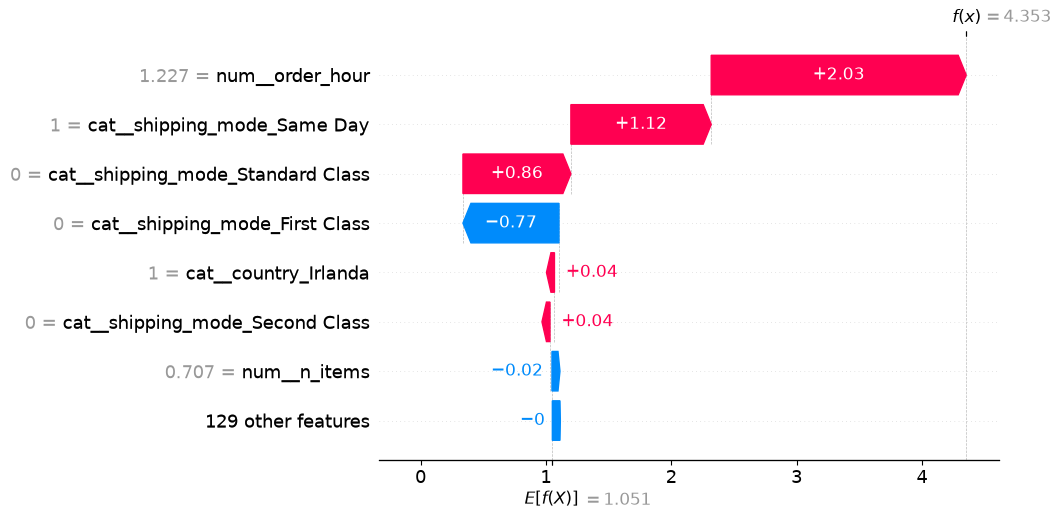

In [4]:
pick = sample[(sample["shipping_mode"] == "Same Day") & (sample["order_hour"] >= 12)].index[0]
i = sample.index.get_loc(pick)
print(sample.loc[pick, ["shipping_mode", "order_hour", "region", "order_value"]])
shap.plots.waterfall(sv[i], max_display=8)